# PCA with scikit-learn

Part 1 shows what PCA does on 2 features you can see. Part 2 runs PCA on the 13 features of Wine. Part 3 clusters Wine without its labels, and Part 4 measures what PCA threw away.

### Table of contents
1. [Part 1: PCA on 2 features you can see](#1.-Part-1:-PCA-on-2-features-you-can-see)
2. [Part 2: PCA on Wine, 13 features](#2.-Part-2:-PCA-on-Wine,-13-features)
3. [Part 3: Wine without labels](#3.-Part-3:-Wine-without-labels)
4. [Part 4: Reconstruction, what PCA threw away](#4.-Part-4:-Reconstruction,-what-PCA-threw-away)
5. [Exercises](#5.-Exercises)

## 1. Part 1: PCA on 2 features you can see

50 points with two features that move together. Two features, but most of the spread lies along one direction.

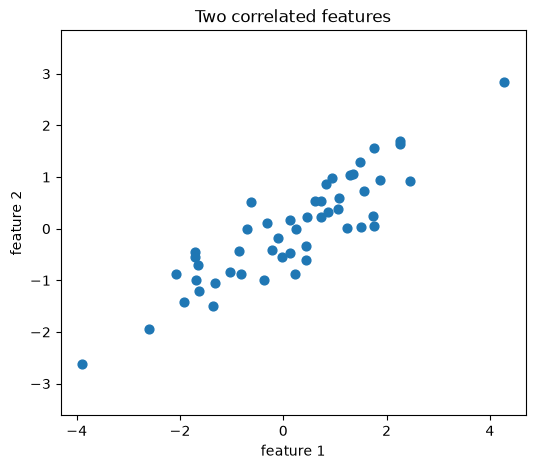

In [25]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
x1 = rng.normal(0, 2, 50)
x2 = 0.6 * x1 + rng.normal(0, 0.6, 50)
X_toy = np.column_stack([x1, x2])

plt.figure(figsize=(6, 5))
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=40)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Two correlated features")
plt.axis("equal")
plt.show()

Fit PCA. `components_` holds the direction of each component, `explained_variance_ratio_` its share of the variance.

In [26]:
from sklearn.decomposition import PCA

pca_toy = PCA()
pca_toy.fit(X_toy)

print("PC1 direction:", pca_toy.components_[0].round(3))
print("PC2 direction:", pca_toy.components_[1].round(3))
print("explained_variance_ratio_:", pca_toy.explained_variance_ratio_.round(3))

PC1 direction: [0.846 0.533]
PC2 direction: [-0.533  0.846]
explained_variance_ratio_: [0.955 0.045]


PC1 alone carries about 95% of the variance. Draw both directions on the data:

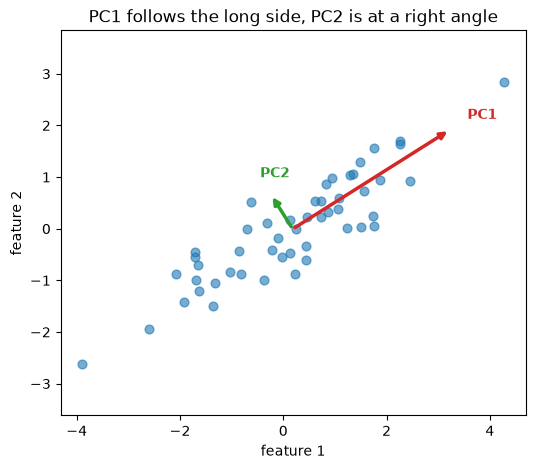

In [27]:
plt.figure(figsize=(6, 5))
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=40, alpha=0.6)
center = pca_toy.mean_
for comp, var, color, name in zip(pca_toy.components_, pca_toy.explained_variance_, ["tab:red", "tab:green"], ["PC1", "PC2"]):
    end = center + comp * 2 * np.sqrt(var)    # arrow length shows the spread along it
    plt.annotate("", xy=end, xytext=center, arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
    plt.text(*(end + comp * 0.4), name, color=color, fontweight="bold")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("PC1 follows the long side, PC2 is at a right angle")
plt.axis("equal")
plt.show()

### The data in the new axes

`transform` gives each point's coordinates along PC1 and PC2. The colors follow each point from one plot to the other.

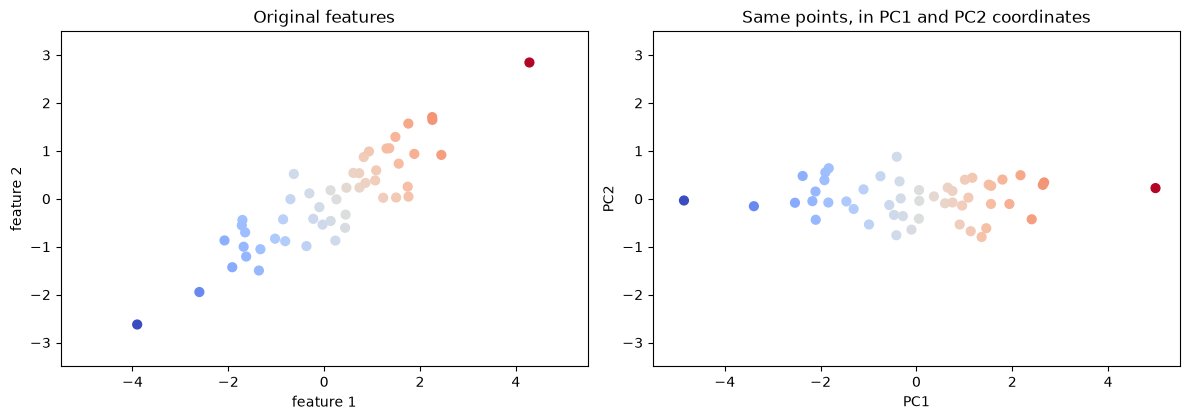

In [28]:
X_toy_pca = pca_toy.transform(X_toy)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_toy[:, 0], X_toy[:, 1], s=40, c=X_toy_pca[:, 0], cmap="coolwarm")
axes[0].set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
axes[0].set_title("Original features")
axes[1].scatter(X_toy_pca[:, 0], X_toy_pca[:, 1], s=40, c=X_toy_pca[:, 0], cmap="coolwarm")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Same points, in PC1 and PC2 coordinates")
for ax in axes:
    ax.set_xlim(-5.5, 5.5)    # same scale on both plots, so only the rotation differs
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Same cloud, turned so the long side lies flat along PC1. Nothing was lost yet: 2 features in, 2 components out.

### Keeping only PC1

In [29]:
pca_1 = PCA(n_components=1)
X_1d = pca_1.fit_transform(X_toy)

print(X_toy.shape, "->", X_1d.shape)

(50, 2) -> (50, 1)


`inverse_transform` goes back to 2 features. Every point lands on the PC1 line: whatever it had along PC2 is gone.

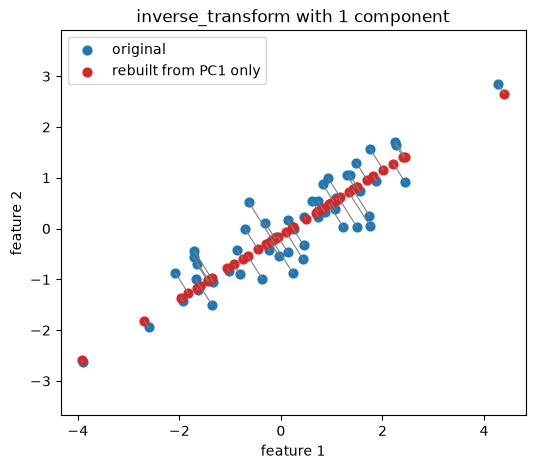

In [30]:
X_back_toy = pca_1.inverse_transform(X_1d)

plt.figure(figsize=(6, 5))
for original, rebuilt in zip(X_toy, X_back_toy):
    plt.plot(*zip(original, rebuilt), color="gray", lw=0.8)
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=40, label="original")
plt.scatter(X_back_toy[:, 0], X_back_toy[:, 1], s=40, color="tab:red", label="rebuilt from PC1 only")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("inverse_transform with 1 component")
plt.legend()
plt.axis("equal")
plt.show()

The gray lines are what PCA threw away. Their average squared length is the **reconstruction error**.

In [31]:
error_toy = ((X_toy - X_back_toy) ** 2).sum(axis=1).mean()
total_spread = ((X_toy - X_toy.mean(axis=0)) ** 2).sum(axis=1).mean()

print("share of the spread lost:     ", round(error_toy / total_spread, 3))
print("PC2's explained_variance_ratio_:", pca_toy.explained_variance_ratio_[1].round(3))

share of the spread lost:      0.045
PC2's explained_variance_ratio_: 0.045


Exactly PC2's share. Dropping a component throws away its variance, and nothing else.

## 2. Part 2: PCA on Wine, 13 features

178 wines, 13 chemical measurements, 3 cultivars. We know this dataset; this time the question is how to see all 13 features at once.

In [32]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("shape:", X.shape)
X.describe().T[["mean", "std", "min", "max"]].round(2)

shape: (178, 13)


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Look at the ranges: `proline` goes into the thousands, `hue` stays below 2.

### The scaling trap

Run PCA on the raw features first:

In [33]:
pca_raw = PCA().fit(X)

print("variance share of PC1:", pca_raw.explained_variance_ratio_[0].round(4))
pd.Series(pca_raw.components_[0], index=X.columns).round(3).sort_values(key=abs, ascending=False).head(4)

variance share of PC1: 0.9981


proline              1.000
magnesium            0.018
alcalinity_of_ash   -0.005
flavanoids           0.002
dtype: float64

PC1 "explains" 99.8% of the variance, but it is just `proline`: the feature with the biggest numbers has the biggest variance. Same trap as K-Means in week 7.

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 13 features to 2 components

`fit_transform` gets only `X_scaled`, never `y`. PCA is unsupervised.

In [35]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(X_scaled.shape, "->", X_pca.shape)

(178, 13) -> (178, 2)


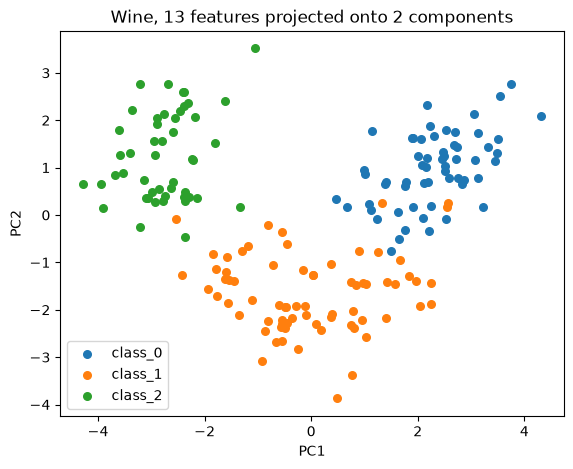

In [36]:
plt.figure(figsize=(6.5, 5))
for cls, name in enumerate(wine.target_names):
    plt.scatter(X_pca[y == cls, 0], X_pca[y == cls, 1], s=30, label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wine, 13 features projected onto 2 components")
plt.legend()
plt.show()

The colors come from `y`, added only now to look at the result. PCA built PC1 and PC2 without them.

### What is PC1?

Each component is a weighted mix of all 13 features. The weights are in `components_`.

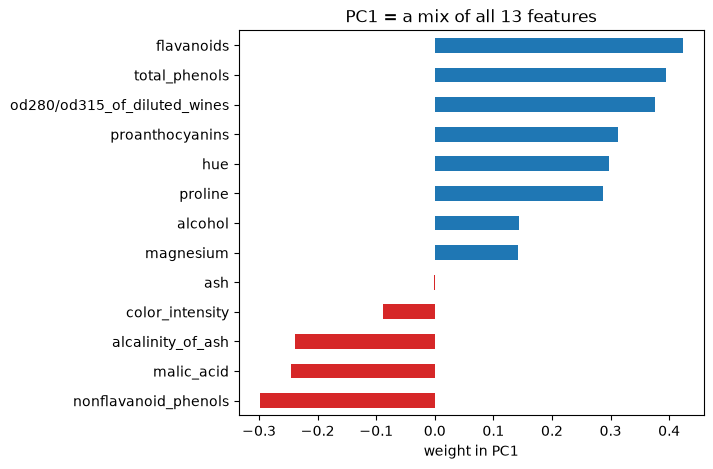

In [37]:
pc1_weights = pd.Series(pca.components_[0], index=X.columns).sort_values()

pc1_weights.plot.barh(figsize=(6, 5), color=np.where(pc1_weights > 0, "tab:blue", "tab:red"))
plt.xlabel("weight in PC1")
plt.title("PC1 = a mix of all 13 features")
plt.show()

Most features contribute, and none dominates. That is why a component has no simple name.

### Explained variance

In [38]:
print("explained_variance_ratio_:", pca.explained_variance_ratio_.round(3))
print("PC1 + PC2 together:       ", pca.explained_variance_ratio_.sum().round(3))

explained_variance_ratio_: [0.362 0.192]
PC1 + PC2 together:        0.554


Fit again without limiting the number of components, to see how the variance adds up:

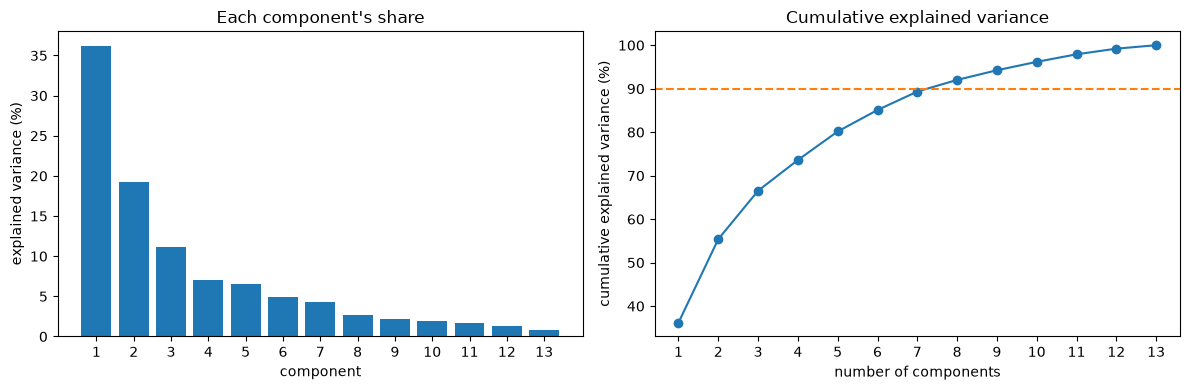

In [39]:
pca_full = PCA().fit(X_scaled)
ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)
n = np.arange(1, len(ratios) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(n, ratios * 100)
axes[0].set_xlabel("component")
axes[0].set_ylabel("explained variance (%)")
axes[0].set_title("Each component's share")
axes[1].plot(n, cumulative * 100, marker="o")
axes[1].axhline(90, color="tab:orange", linestyle="--")
axes[1].set_xlabel("number of components")
axes[1].set_ylabel("cumulative explained variance (%)")
axes[1].set_title("Cumulative explained variance")
for ax in axes:
    ax.set_xticks(n)
plt.tight_layout()
plt.show()

### Choosing n_components

Instead of a fixed number, give the share of variance to keep. `sklearn` finds how many components that takes.

In [40]:
pca_90 = PCA(n_components=0.90)
X_pca_90 = pca_90.fit_transform(X_scaled)

print("components needed:", pca_90.n_components_)
print("variance kept:    ", pca_90.explained_variance_ratio_.sum().round(3))

components needed: 8
variance kept:     0.92


For a plot, 2 components are enough. For a model, aim for roughly 80 to 95%. The right number depends on the goal.

## 3. Part 3: Wine without labels

The rule for this part: pretend `y` does not exist until the very end. Week 7's recipe gets one extra step: `Scaling -> PCA -> K-Means`.

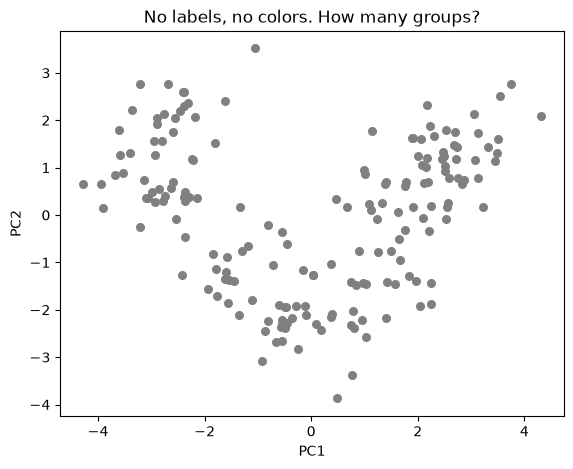

In [41]:
plt.figure(figsize=(6.5, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=30, color="gray")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("No labels, no colors. How many groups?")
plt.show()

### Choosing k

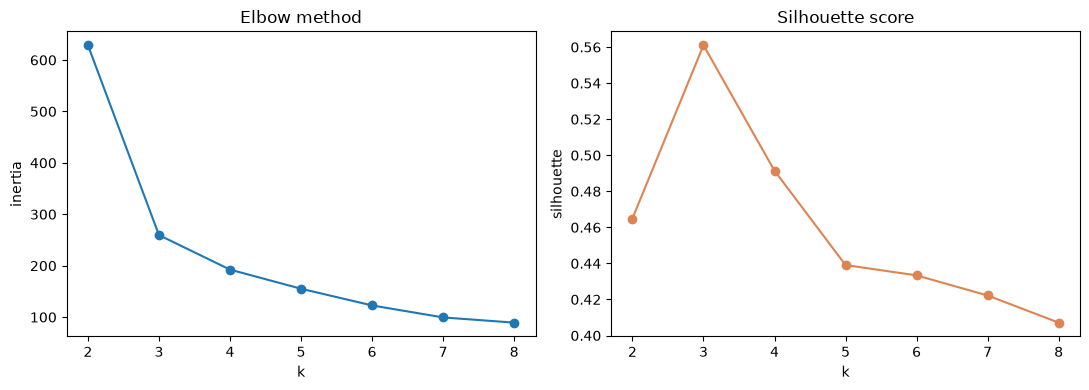

In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, silhouettes = [], []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_pca, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(2, 9), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[1].plot(range(2, 9), silhouettes, marker="o", color="#DD8452")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette")
plt.tight_layout()
plt.show()

Both point to `k=3`: the elbow bends there and the silhouette peaks.

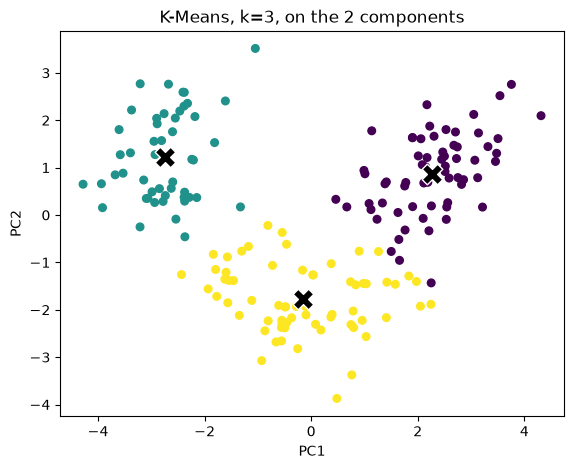

In [43]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

plt.figure(figsize=(6.5, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=30, c=clusters, cmap="viridis")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="X", s=220, c="black", edgecolor="white")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means, k=3, on the 2 components")
plt.show()

### Revealing the labels

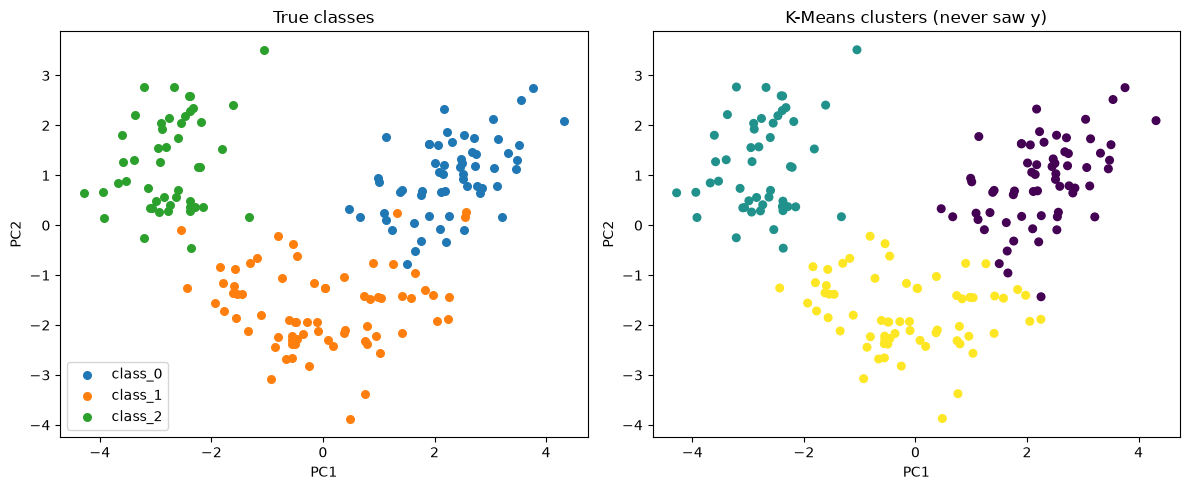

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for cls, name in enumerate(wine.target_names):
    axes[0].scatter(X_pca[y == cls, 0], X_pca[y == cls, 1], s=30, label=name)
axes[0].set_title("True classes")
axes[0].legend()
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], s=30, c=clusters, cmap="viridis")
axes[1].set_title("K-Means clusters (never saw y)")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

In [45]:
pd.crosstab(y, clusters, rownames=["true class"], colnames=["cluster"])

cluster,0,1,2
true class,,,
0,59,0,0
1,5,1,65
2,0,48,0


Cluster numbers are arbitrary, so read the table by rows. Only 6 of 178 wines land with another class. `adjusted_rand_score` from week 7 puts it in one number (1.0 = identical groups):

In [46]:
from sklearn.metrics import adjusted_rand_score

print(f"agreement with the true classes: {adjusted_rand_score(y, clusters):.3f}")

agreement with the true classes: 0.895


Clusters do not have to match the classes: K-Means never knew what a class was. Here they happen to match closely.

### Clustering with vs. without PCA

In [47]:
kmeans_full = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_full = kmeans_full.fit_predict(X_scaled)

print(f"silhouette, K-Means on 13 scaled features: {silhouette_score(X_scaled, clusters_full):.2f}")
print(f"silhouette, K-Means on 2 PCA components:   {silhouette_score(X_pca, clusters):.2f}")

silhouette, K-Means on 13 scaled features: 0.28
silhouette, K-Means on 2 PCA components:   0.56


The silhouette doubled. Did PCA find better clusters, or just make them look tighter? Compare the groups themselves:

In [48]:
print(f"agreement between the two clusterings:   {adjusted_rand_score(clusters_full, clusters):.3f}")
print(f"agreement with true classes, without PCA: {adjusted_rand_score(y, clusters_full):.3f}")
print(f"agreement with true classes, with PCA:    {adjusted_rand_score(y, clusters):.3f}")
print(f"silhouette of the 13-feature clusters, measured in 2D: {silhouette_score(X_pca, clusters_full):.2f}")

agreement between the two clusterings:   0.932
agreement with true classes, without PCA: 0.897
agreement with true classes, with PCA:    0.895
silhouette of the 13-feature clusters, measured in 2D: 0.56


Almost the same groups. The silhouette rose because distances in 2D ignore the 45% of variance we dropped, so every cluster looks tighter. PCA made the clustering simpler and plottable; it did not find better groups.

## 4. Part 4: Reconstruction, what PCA threw away

Same as Part 1: `inverse_transform` rebuilds all 13 features from the 8 components.

In [49]:
X_back = pca_90.inverse_transform(X_pca_90)
print(X_scaled.shape, "->", X_pca_90.shape, "->", X_back.shape)

error = ((X_scaled - X_back) ** 2).mean()
print("reconstruction error:", error.round(3))
print("variance dropped:    ", (1 - pca_90.explained_variance_ratio_.sum()).round(3))

(178, 13) -> (178, 8) -> (178, 13)
reconstruction error: 0.08
variance dropped:     0.08


On scaled data, the reconstruction error is exactly the share of variance we dropped. Now for every possible number of components:

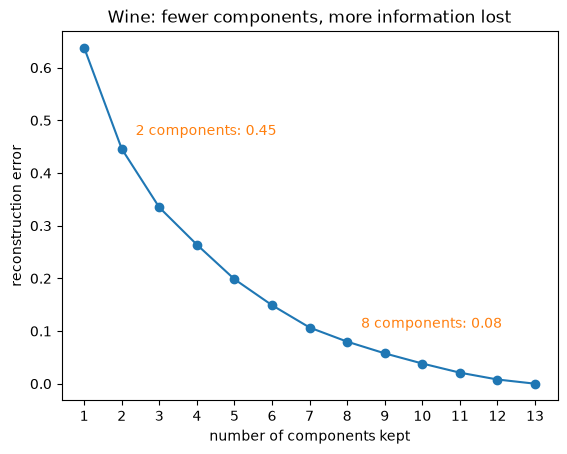

In [50]:
errors = []
for k in range(1, 14):
    pca_k = PCA(n_components=k).fit(X_scaled)
    errors.append(((X_scaled - pca_k.inverse_transform(pca_k.transform(X_scaled))) ** 2).mean())

plt.plot(range(1, 14), errors, marker="o")
for k in [2, 8]:
    plt.annotate(f"{k} components: {errors[k - 1]:.2f}", (k, errors[k - 1]), xytext=(10, 10),
                 textcoords="offset points", color="tab:orange")
plt.xticks(range(1, 14))
plt.xlabel("number of components kept")
plt.ylabel("reconstruction error")
plt.title("Wine: fewer components, more information lost")
plt.show()

### Seeing the loss: Digits

With images, the loss is visible. Digits from week 5: 8x8 images, 64 pixels each. All pixels share the same 0 to 16 scale, so no scaling is needed.

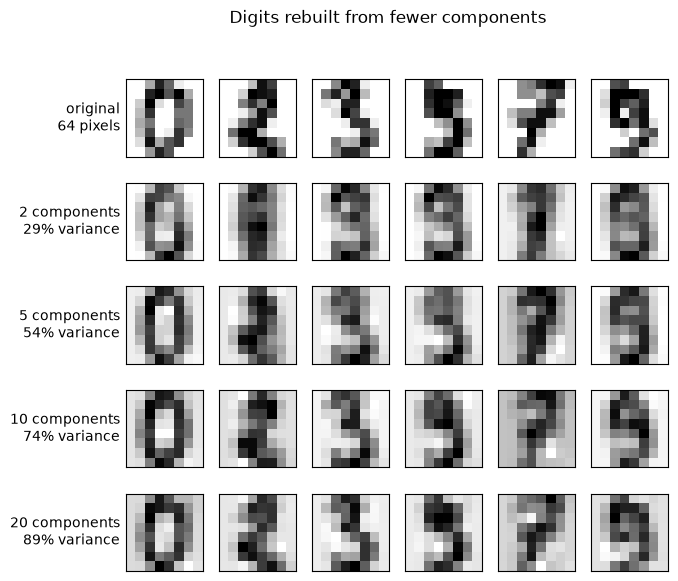

In [51]:
from sklearn.datasets import load_digits

X_digits = load_digits().data
examples = X_digits[[0, 2, 3, 5, 7, 9]]   # the first rows are the digits 0 to 9, in order

ks = [2, 5, 10, 20]
fig, axes = plt.subplots(len(ks) + 1, len(examples), figsize=(7, 6.5))
for col, image in enumerate(examples):
    axes[0, col].imshow(image.reshape(8, 8), cmap="binary")
axes[0, 0].set_ylabel("original\n64 pixels", rotation=0, ha="right", va="center")
for row, k in enumerate(ks, start=1):
    pca_k = PCA(n_components=k).fit(X_digits)
    rebuilt = pca_k.inverse_transform(pca_k.transform(examples))
    for col, image in enumerate(rebuilt):
        axes[row, col].imshow(image.reshape(8, 8), cmap="binary")
    axes[row, 0].set_ylabel(f"{k} components\n{pca_k.explained_variance_ratio_.sum():.0%} variance",
                            rotation=0, ha="right", va="center")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Digits rebuilt from fewer components")
plt.show()

With 20 of 64 dimensions the digits are still easy to read. That is PCA as compression.

### One more look at the error

PCA learns the main directions of most samples. A sample it rebuilds badly is not like the others: that idea opens the next notebook, on anomaly detection.

## 5. Exercises

1. **Part 1:** change `0.6 * x1` to `0.1 * x1`, so the two features barely move together. Rerun Part 1. What happens to PC1's share of the variance, and to the reconstruction error?

2. **Wine:** how many components keep 80% of the variance? 95%?
3. **Wine:** plot PC1 against PC3 instead of PC2, colored by class. Do the classes still separate?
4. **Wine:** find the 3 features with the largest weights in PC2, positive or negative. How would you describe PC2 in words?
5. **With vs. without PCA:** rerun the comparison with `pca_90` (8 components) instead of 2. Does the silhouette still double? Why?
6. **Digits:** what is the smallest number of components at which you can still read all six digits? What share of the variance is that?